# MoDL MRI reconstruction across acceleration rates

This notebook records the completed **2×, 4×, 6×, and 8×** experiments. Each model
received **50 passes / 94,900 updates** and was selected independently using only
volume-averaged validation PSNR before one held-out test evaluation. The implementation
alternates a shared CNN regularizer with conjugate-gradient data-consistency solves.

References: [MoDL paper](https://arxiv.org/abs/1712.02862) ·
[official MoDL repository](https://github.com/hkaggarwal/modl)

In [1]:
from pathlib import Path
import json, re
import matplotlib.pyplot as plt
import numpy as np
from html import escape
from IPython.display import HTML, Image, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RATES = (2, 4, 6, 8)
MODL_ROOTS = {rate: Path(f'/data/david_agyei/nyu-dataset/derived/modl_{rate}x_fp32')
              for rate in RATES}
RDBM_ROOT = Path('/data/david_agyei/nyu-dataset/derived/rdbm_full_bf16')

def read_json(path):
    return json.loads(Path(path).read_text())

def show_table(rows, columns, precision=4, bold_best=None, bold_pairs=None):
    bold_best = bold_best or {}
    bold_pairs = bold_pairs or []
    bold_cells = set()
    for key, direction in bold_best.items():
        values = [row[key] for row in rows if isinstance(row.get(key), (int, float)) and np.isfinite(row[key])]
        if values:
            best = (max if direction == 'max' else min)(values)
            bold_cells.update((index, key) for index, row in enumerate(rows)
                              if isinstance(row.get(key), (int, float)) and np.isclose(row[key], best))
    for left, right, direction in bold_pairs:
        for index, row in enumerate(rows):
            values = [row[left], row[right]]
            best = (max if direction == 'max' else min)(values)
            if np.isclose(row[left], best): bold_cells.add((index, left))
            if np.isclose(row[right], best): bold_cells.add((index, right))
    def render(value):
        if isinstance(value, float):
            return f'{value:.{precision}f}'
        return escape(str(value))
    header = ''.join(f'<th style="text-align:left;padding:4px 10px">{escape(label)}</th>' for _, label in columns)
    body = ''.join('<tr>' + ''.join(
        f'<td style="text-align:left;padding:4px 10px">'
        f'{"<strong>" if (index,key) in bold_cells else ""}{render(row[key])}'
        f'{"</strong>" if (index,key) in bold_cells else ""}</td>' for key, _ in columns
    ) + '</tr>' for index, row in enumerate(rows))
    display(HTML(f'<table><thead><tr>{header}</tr></thead><tbody>{body}</tbody></table>'))

selections = {rate: read_json(MODL_ROOTS[rate]/'evaluation/best_validation_checkpoint.json')
              for rate in RATES}
ablation_selections = {
    rate: read_json(MODL_ROOTS[rate]/'evaluation/unroll_ablation/selection.json')
    for rate in RATES
}
ablation_summaries = {
    rate: read_json(
        MODL_ROOTS[rate]/'evaluation/unroll_ablation'/
        f"step-{selections[rate]['checkpoint_step']:07d}"/'summary.json'
    )
    for rate in RATES
}
test_dirs = {rate: MODL_ROOTS[rate]/'evaluation/test'/f"step-{selections[rate]['checkpoint_step']:07d}"
             for rate in RATES}
tests = {rate: read_json(test_dirs[rate]/'summary.json') for rate in RATES}
selection, selected_step, test = selections[4], selections[4]['checkpoint_step'], tests[4]
rdbm = read_json(RDBM_ROOT / 'evaluation/test/step-0094900/summary.json')
progression = read_json(ROOT / 'results/modl_evaluation/qualitative/progression_metadata.json')
print('Selected checkpoints: ' + ', '.join(
    f"{rate}× step {selections[rate]['checkpoint_step']:,}" for rate in RATES))

Selected checkpoints: 2× step 94,900, 4× step 37,960, 6× step 18,980, 8× step 18,980


## Experiment integrity

The split is volume-level, so slices from a subject volume cannot leak between train,
validation, and test. Every rate uses the same cohort and supplied sensitivity maps,
with a separately trained model and the corresponding deterministic sampling mask.

In [2]:
integrity = [
    {'Split': 'Train', 'Volumes': 120, 'Slices': 1898, 'Use': 'optimization'},
    {'Split': 'Validation', 'Volumes': 14, 'Slices': 220, 'Use': 'checkpoint selection'},
    {'Split': 'Test', 'Volumes': tests[4]['volume_count'], 'Slices': tests[4]['slice_count'], 'Use': 'final reporting'},
]
show_table(integrity, [(key, key) for key in ['Split', 'Volumes', 'Slices', 'Use']], precision=0)
print('Training schedule: 5 warm-up epochs with 1 unroll, then 45 epochs with 10 unrolls.')

Split,Volumes,Slices,Use
Train,120,1898,optimization
Validation,14,220,checkpoint selection
Test,14,218,final reporting


Training schedule: 5 warm-up epochs with 1 unroll, then 45 epochs with 10 unrolls.


## Training trajectory

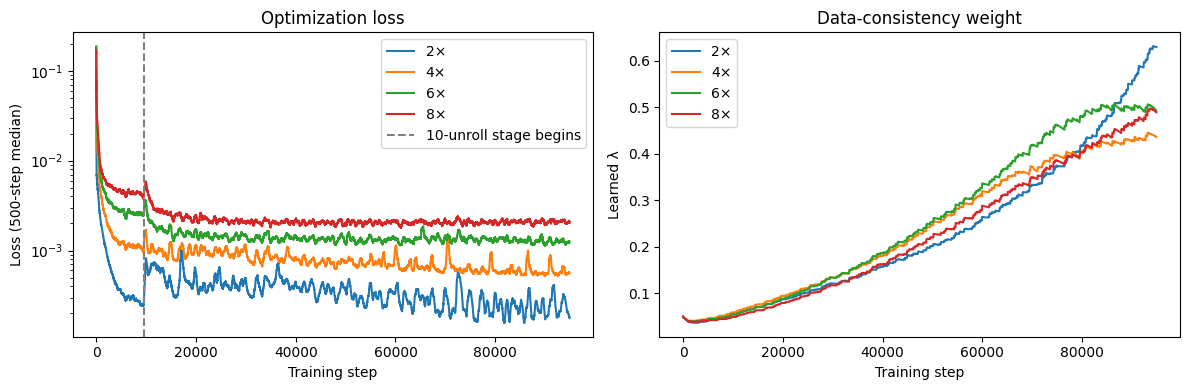

Rate,Final loss,Final λ
2×,0.000233,0.629588
4×,0.000429,0.436137
6×,0.001202,0.492369
8×,0.001940,0.489311


In [3]:
pattern = re.compile(r'step=(\d+).*?loss=([0-9.eE+-]+).*?lambda=([0-9.eE+-]+)')
def training_records(root):
    records = []
    for log_name in ['train_k1.log', 'train_k10.log']:
        for line in (root/log_name).read_text().splitlines():
            match = pattern.search(line)
            if match: records.append((int(match[1]), float(match[2]), float(match[3])))
    return sorted(dict((step, (loss, lam)) for step, loss, lam in records).items())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
final_training = []
for rate in RATES:
    records = training_records(MODL_ROOTS[rate])
    steps = np.array([row[0] for row in records])
    losses = np.array([row[1][0] for row in records])
    lambdas = np.array([row[1][1] for row in records])
    window = 500
    loss_smooth = np.array([np.median(losses[max(0, i-window+1):i+1]) for i in range(len(losses))])
    axes[0].plot(steps, loss_smooth, label=f'{rate}×')
    axes[1].plot(steps, lambdas, label=f'{rate}×')
    final_training.append({'Rate':f'{rate}×','Final loss':losses[-1],'Final λ':lambdas[-1]})
axes[0].axvline(9_490, color='gray', linestyle='--', label='10-unroll stage begins')
axes[0].set(xlabel='Training step', ylabel='Loss (500-step median)', title='Optimization loss')
axes[0].set_yscale('log'); axes[0].legend()
axes[1].set(xlabel='Training step', ylabel='Learned λ', title='Data-consistency weight')
axes[1].legend()
plt.tight_layout(); plt.show()
show_table(final_training, [(key,key) for key in final_training[0]], precision=6)

## Validation checkpoint selection

Five evenly spaced checkpoints were evaluated on all 14 validation volumes. Metrics are
first averaged over slices within each volume, then averaged equally across volumes.
The test set did not participate in this choice.

Rate,Step,PSNR,SSIM,NMSE
2×,94900,40.1790,0.8370,0.0046
4×,37960,35.3217,0.8107,0.0136
6×,18980,31.7187,0.7819,0.0313
8×,18980,29.3661,0.7649,0.0520


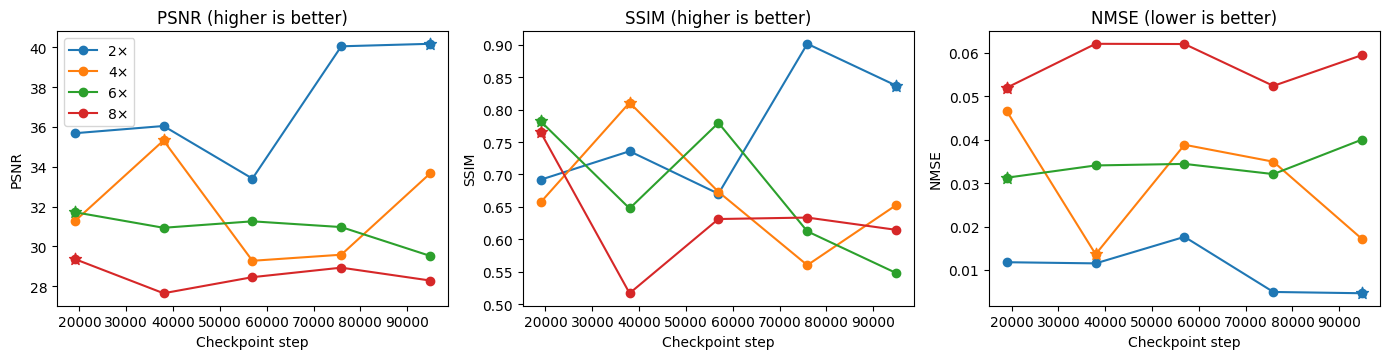

Stars mark the independently selected maximum-PSNR checkpoint for each rate.


In [4]:
selected = [{'Rate':f'{rate}×','Step':selections[rate]['checkpoint_step'],
             'PSNR':selections[rate]['validation_metrics']['psnr'],
             'SSIM':selections[rate]['validation_metrics']['ssim'],
             'NMSE':selections[rate]['validation_metrics']['nmse']}
            for rate in RATES]
show_table(selected, [(key,key) for key in selected[0]])

fig, axes = plt.subplots(1, 3, figsize=(14, 3.7))
for rate in RATES:
    validation = [{'Step':row['checkpoint_step'],
                   **{key.upper():value for key,value in row['modl'].items()}}
                  for row in selections[rate]['candidates']]
    for axis, metric, better in zip(axes, ['PSNR', 'SSIM', 'NMSE'], ['higher', 'higher', 'lower']):
        axis.plot([row['Step'] for row in validation], [row[metric] for row in validation],
                  marker='o', label=f'{rate}×')
        chosen = next(row for row in validation if row['Step'] == selections[rate]['checkpoint_step'])
        axis.scatter([chosen['Step']], [chosen[metric]], marker='*', s=80)
        axis.set(xlabel='Checkpoint step', ylabel=metric, title=f'{metric} ({better} is better)')
axes[0].legend()
plt.tight_layout(); plt.show()
print('Stars mark the independently selected maximum-PSNR checkpoint for each rate.')

## No-retraining early-exit ablation

After training, every intermediate output from unrolls 1--10 was evaluated on the
**validation split only** across all five checkpoints. This tests whether stopping the
existing MoDL model early improves reconstruction quality; no weights were changed and
the test split was not used to choose an exit.

The locked recommendation is **stage 7 at 2×** and **stage 10 at 4×, 6×, and 8×**.
At 2×, stage 7 improves validation PSNR, SSIM, and NMSE over stage 10. At the other
rates, earlier exits can raise SSIM, but only by reducing PSNR and worsening NMSE.

In [5]:
locked_exits = {2: 7, 4: 10, 6: 10, 8: 10}
ablation_rows = []
for rate in RATES:
    selected_stage = locked_exits[rate]
    stages = ablation_summaries[rate]['stages']
    full = stages['10']['modl']
    selected_exit = stages[str(selected_stage)]['modl']
    ablation_rows.append({
        'Rate': f'{rate}×',
        'Locked exit': selected_stage,
        'Stage 10 PSNR': full['psnr'], 'Locked PSNR': selected_exit['psnr'],
        'Stage 10 SSIM': full['ssim'], 'Locked SSIM': selected_exit['ssim'],
        'Stage 10 NMSE': full['nmse'], 'Locked NMSE': selected_exit['nmse'],
    })
show_table(ablation_rows, [(key, key) for key in ablation_rows[0]], bold_pairs=[
    ('Stage 10 PSNR', 'Locked PSNR', 'max'),
    ('Stage 10 SSIM', 'Locked SSIM', 'max'),
    ('Stage 10 NMSE', 'Locked NMSE', 'min'),
])

selection_rows = []
for rate in RATES:
    result = ablation_selections[rate]
    selection_rows.append({
        'Rate': f'{rate}×',
        'Best PSNR stage': result['best_psnr']['unroll'],
        'Best SSIM stage': result['best_ssim']['unroll'],
        'Best NMSE stage': result['best_nmse']['unroll'],
        'Locked stage': locked_exits[rate],
    })
show_table(selection_rows, [(key, key) for key in selection_rows[0]], precision=0)

Rate,Locked exit,Stage 10 PSNR,Locked PSNR,Stage 10 SSIM,Locked SSIM,Stage 10 NMSE,Locked NMSE
2×,7,40.1790,40.5778,0.8370,0.8982,0.0046,0.0045
4×,10,35.3217,35.3217,0.8107,0.8107,0.0136,0.0136
6×,10,31.7187,31.7187,0.7819,0.7819,0.0313,0.0313
8×,10,29.3661,29.3661,0.7649,0.7649,0.0520,0.0520


Rate,Best PSNR stage,Best SSIM stage,Best NMSE stage,Locked stage
2×,7,2,8,7
4×,10,1,10,10
6×,10,2,10,10
8×,10,5,10,10


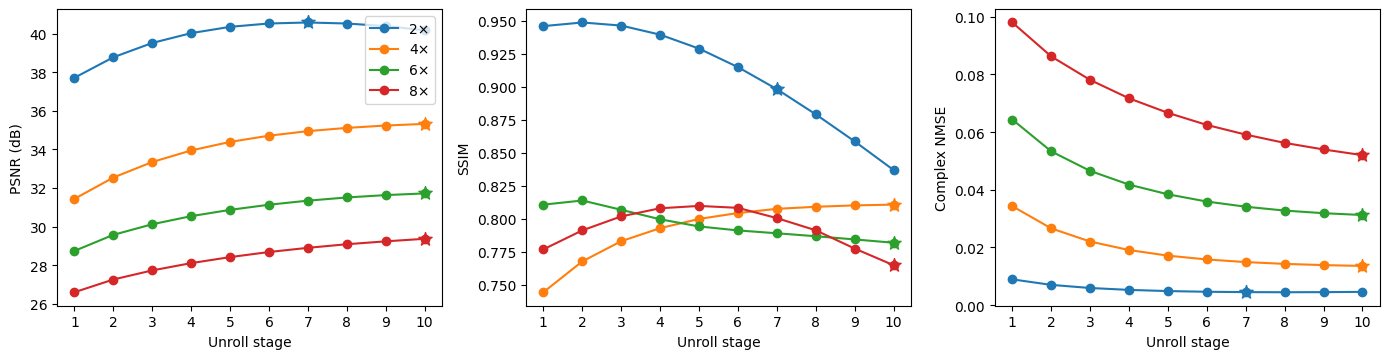

Stars mark the locked validation-selected exit. The held-out test results below remain the original stage-10 results.


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.7))
for rate in RATES:
    stages = ablation_summaries[rate]['stages']
    unrolls = np.arange(1, 11)
    values = {metric: [stages[str(stage)]['modl'][metric] for stage in unrolls]
              for metric in ['psnr', 'ssim', 'nmse']}
    for axis, metric, label in zip(axes, ['psnr', 'ssim', 'nmse'],
                                   ['PSNR (dB)', 'SSIM', 'Complex NMSE']):
        axis.plot(unrolls, values[metric], marker='o', label=f'{rate}×')
        exit_stage = locked_exits[rate]
        axis.scatter([exit_stage], [values[metric][exit_stage-1]], marker='*', s=100)
        axis.set(xlabel='Unroll stage', ylabel=label, xticks=unrolls)
axes[0].legend()
plt.tight_layout(); plt.show()
print('Stars mark the locked validation-selected exit. The held-out test results below remain the original stage-10 results.')

## Held-out test results across acceleration rates

Rate,Selected step,ZF PSNR,MoDL PSNR,PSNR gain,ZF SSIM,MoDL SSIM,ZF NMSE,MoDL NMSE,ZF residual,MoDL residual,Seconds/slice
2×,94900,35.9877,39.6646,3.6770,0.9304,0.8305,0.0200,0.0257,0.2021,0.1970,0.0570
4×,37960,29.7164,34.8049,5.0885,0.8295,0.8024,0.0714,0.1104,0.1622,0.1474,0.0538
6×,18980,26.8159,30.8370,4.0211,0.7736,0.7660,0.1184,0.1588,0.1542,0.1306,0.0557
8×,18980,25.3353,29.8164,4.4811,0.7441,0.7639,0.1564,0.2190,0.1470,0.1128,0.0555


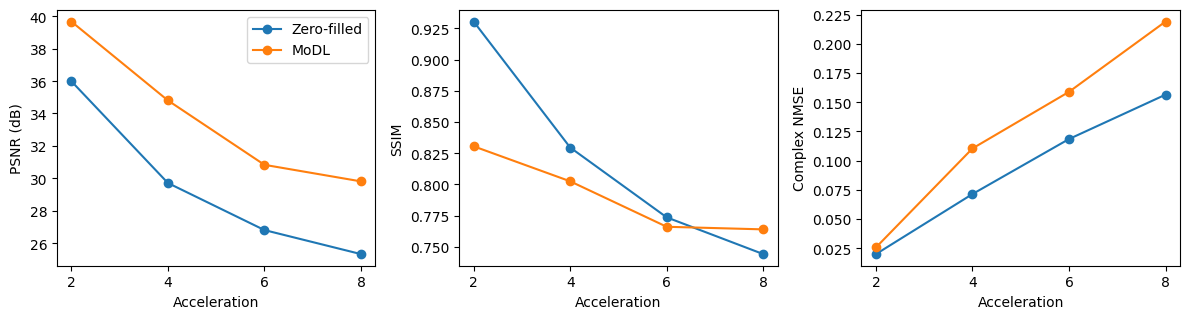

In [7]:
rate_results = []
for rate in RATES:
    baseline, result = tests[rate]['zero_filled'], tests[rate]['modl']
    rate_results.append({
        'Rate':f'{rate}×','Selected step':selections[rate]['checkpoint_step'],
        'ZF PSNR':baseline['psnr'],'MoDL PSNR':result['psnr'],
        'PSNR gain':result['psnr']-baseline['psnr'],
        'ZF SSIM':baseline['ssim'],'MoDL SSIM':result['ssim'],
        'ZF NMSE':baseline['nmse'],'MoDL NMSE':result['nmse'],
        'ZF residual':baseline['measurement_residual'],'MoDL residual':result['measurement_residual'],
        'Seconds/slice':result['seconds_per_slice']})
show_table(rate_results, [(key,key) for key in rate_results[0]], bold_pairs=[
    ('ZF PSNR','MoDL PSNR','max'), ('ZF SSIM','MoDL SSIM','max'),
    ('ZF NMSE','MoDL NMSE','min'), ('ZF residual','MoDL residual','min')])

x=np.array(RATES)
fig,axes=plt.subplots(1,3,figsize=(12,3.3))
for axis,key,ylabel in [(axes[0],'psnr','PSNR (dB)'),(axes[1],'ssim','SSIM'),(axes[2],'nmse','Complex NMSE')]:
    axis.plot(x,[tests[r]['zero_filled'][key] for r in RATES],marker='o',label='Zero-filled')
    axis.plot(x,[tests[r]['modl'][key] for r in RATES],marker='o',label='MoDL')
    axis.set(xlabel='Acceleration',ylabel=ylabel,xticks=x)
axes[0].legend(); plt.tight_layout(); plt.show()

## Detailed 4× test comparison

In [8]:
comparison = []
for name, metrics in [('Zero-filled', test['zero_filled']), ('MoDL', test['modl']), ('RDBM', rdbm['rdbm'])]:
    comparison.append({
        'Method': name,
        'Complex NMSE ↓': metrics['nmse'],
        'Magnitude PSNR ↑': metrics['psnr'],
        'Magnitude SSIM ↑': metrics['ssim'],
        'Measurement residual ↓': metrics['measurement_residual'],
        'Seconds/slice ↓': metrics.get('seconds_per_slice', np.nan),
    })
show_table(comparison, [(key, key) for key in comparison[0]], bold_best={
    'Complex NMSE ↓':'min', 'Magnitude PSNR ↑':'max', 'Magnitude SSIM ↑':'max',
    'Measurement residual ↓':'min', 'Seconds/slice ↓':'min'})

psnr_gain = test['modl']['psnr'] - test['zero_filled']['psnr']
ssim_change = test['modl']['ssim'] - test['zero_filled']['ssim']
speedup = rdbm['rdbm']['seconds_per_slice'] / test['modl']['seconds_per_slice']
print(f'MoDL vs zero-filled: {psnr_gain:+.2f} dB PSNR and {ssim_change:+.4f} SSIM.')
print(f'MoDL is approximately {speedup:.2f}× faster per slice than this RDBM evaluation.')

Method,Complex NMSE ↓,Magnitude PSNR ↑,Magnitude SSIM ↑,Measurement residual ↓,Seconds/slice ↓
Zero-filled,0.0714,29.7164,0.8295,0.1622,nan
MoDL,0.1104,34.8049,0.8024,0.1474,0.0538
RDBM,0.0559,35.6007,0.9207,0.1450,0.1916


MoDL vs zero-filled: +5.09 dB PSNR and -0.0271 SSIM.
MoDL is approximately 3.56× faster per slice than this RDBM evaluation.


### 4× results by acquisition

This breakdown exposes behavior hidden by the overall mean. The small AXFLAIR subset
contains one strong complex-NMSE outlier, while both T1 groups improve in complex NMSE.

Acquisition,Volumes,ZF PSNR,MoDL PSNR,ZF SSIM,MoDL SSIM,ZF NMSE,MoDL NMSE
AXFLAIR,2,28.5068,31.8588,0.7856,0.7758,0.1538,0.6124
AXT1POST,10,29.9895,35.1425,0.8333,0.8051,0.0560,0.0289
AXT1PRE,2,29.5610,36.0630,0.8545,0.8156,0.0655,0.0157


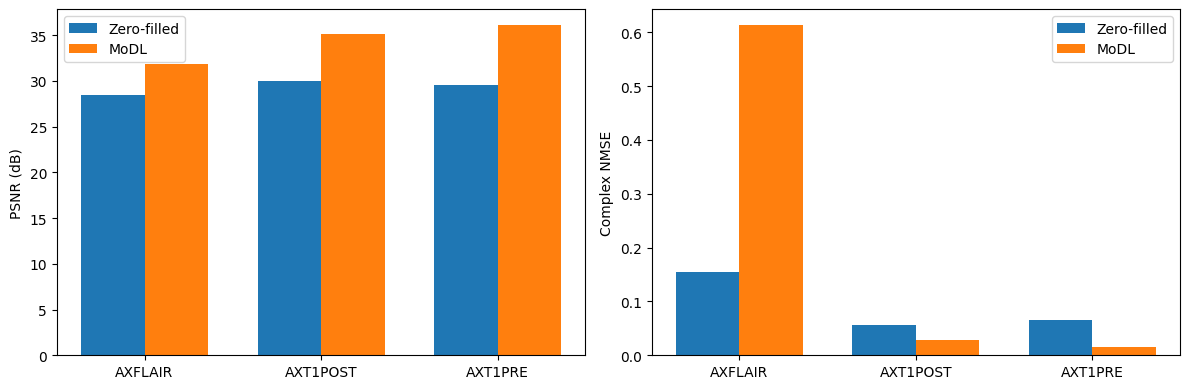

In [9]:
acquisition_rows = []
for acquisition, group in test['by_acquisition'].items():
    acquisition_rows.append({
        'Acquisition': acquisition,
        'Volumes': group['volume_count'],
        'ZF PSNR': group['zero_filled']['psnr'], 'MoDL PSNR': group['modl']['psnr'],
        'ZF SSIM': group['zero_filled']['ssim'], 'MoDL SSIM': group['modl']['ssim'],
        'ZF NMSE': group['zero_filled']['nmse'], 'MoDL NMSE': group['modl']['nmse'],
    })
acquisition = acquisition_rows
show_table(acquisition, [(key, key) for key in acquisition[0]])

x = np.arange(len(acquisition)); width = 0.36
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(x-width/2, [row['ZF PSNR'] for row in acquisition], width, label='Zero-filled')
axes[0].bar(x+width/2, [row['MoDL PSNR'] for row in acquisition], width, label='MoDL')
axes[0].set_xticks(x, [row['Acquisition'] for row in acquisition]); axes[0].set_ylabel('PSNR (dB)'); axes[0].legend()
axes[1].bar(x-width/2, [row['ZF NMSE'] for row in acquisition], width, label='Zero-filled')
axes[1].bar(x+width/2, [row['MoDL NMSE'] for row in acquisition], width, label='MoDL')
axes[1].set_xticks(x, [row['Acquisition'] for row in acquisition]); axes[1].set_ylabel('Complex NMSE'); axes[1].legend()
plt.tight_layout(); plt.show()

## 4× per-volume behavior

volume_id,acquisition,ZF PSNR,MoDL PSNR,ZF NMSE,MoDL NMSE,PSNR gain
file_brain_AXFLAIR_202_6000575,AXFLAIR,26.0292,27.9485,0.2509,1.2020,1.9192
file_brain_AXT1POST_208_2080524,AXT1POST,30.6380,33.9667,0.0475,0.0170,3.3288
file_brain_AXT1POST_209_6001292,AXT1POST,31.4362,35.7325,0.0339,0.0117,4.2963
file_brain_AXT1POST_203_6000895,AXT1POST,28.3800,32.8834,0.1054,0.1716,4.5034
file_brain_AXFLAIR_203_6000916,AXFLAIR,30.9845,35.7692,0.0568,0.0228,4.7847
file_brain_AXT1POST_207_2070199,AXT1POST,29.5718,34.4661,0.0614,0.0159,4.8944
file_brain_AXT1POST_203_6000889,AXT1POST,29.6845,34.7624,0.0525,0.0150,5.0779
file_brain_AXT1PRE_201_6002729,AXT1PRE,28.6553,34.1693,0.0732,0.0222,5.5140
file_brain_AXT1POST_207_2070244,AXT1POST,29.6877,35.4217,0.0620,0.0143,5.7340
file_brain_AXT1POST_205_2050014,AXT1POST,30.2209,35.9621,0.0703,0.0138,5.7412


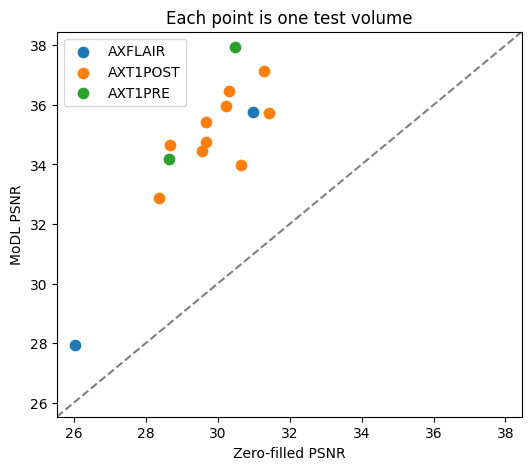

In [10]:
volumes = [{
    'volume_id': item['volume_id'], 'acquisition': item['acquisition'],
    'ZF PSNR': item['zero_filled']['psnr'], 'MoDL PSNR': item['modl']['psnr'],
    'ZF NMSE': item['zero_filled']['nmse'], 'MoDL NMSE': item['modl']['nmse'],
} for item in test['volumes']]
for row in volumes:
    row['PSNR gain'] = row['MoDL PSNR'] - row['ZF PSNR']
show_table(sorted(volumes, key=lambda row: row['PSNR gain']), [(key, key) for key in volumes[0]])

fig, ax = plt.subplots(figsize=(6, 5))
for acquisition in sorted(set(row['acquisition'] for row in volumes)):
    group = [row for row in volumes if row['acquisition'] == acquisition]
    ax.scatter([row['ZF PSNR'] for row in group], [row['MoDL PSNR'] for row in group], label=acquisition, s=55)
all_psnr = [row[key] for row in volumes for key in ['ZF PSNR', 'MoDL PSNR']]
limits = [min(all_psnr) - .5, max(all_psnr) + .5]
ax.plot(limits, limits, '--', color='gray'); ax.set_xlim(limits); ax.set_ylim(limits)
ax.set(xlabel='Zero-filled PSNR', ylabel='MoDL PSNR', title='Each point is one test volume')
ax.legend(); plt.show()

## 4× reconstruction progression

The first row shows magnitude images; the second shows absolute error against the target.
The example was chosen automatically as the test slice closest to the median MoDL PSNR
gain, avoiding hand-picking the best-looking result.

Sample: file_brain_AXT1POST_203_6000889:8 (index 88)


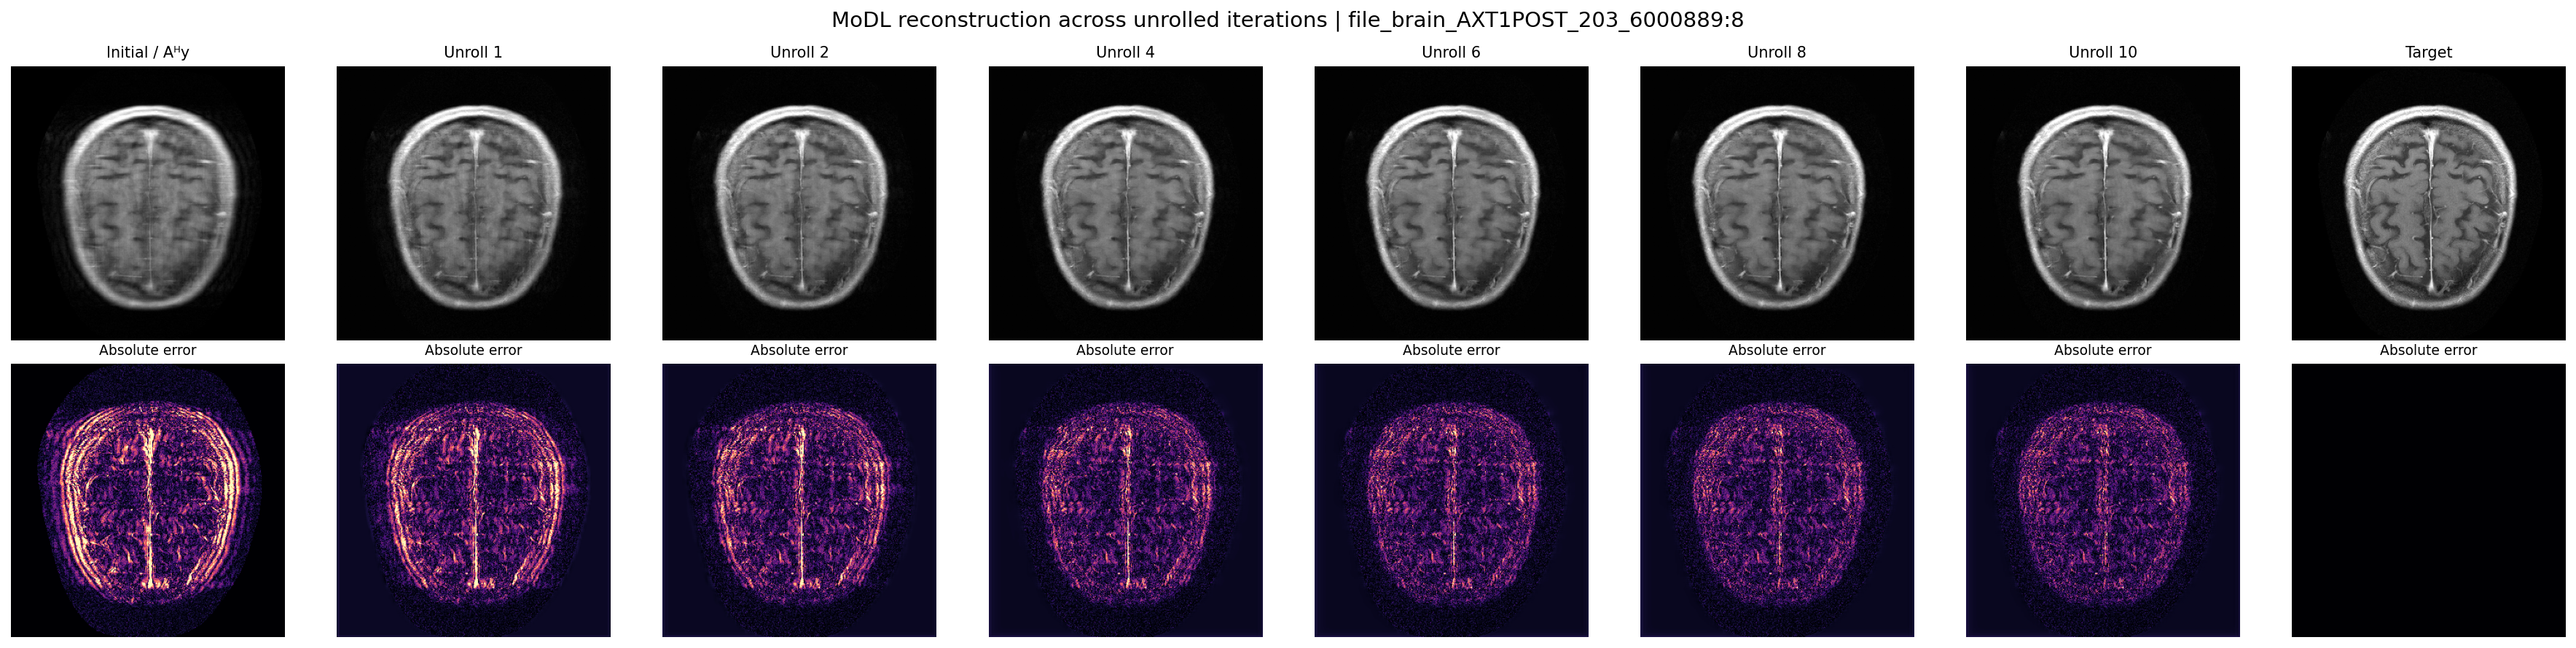

In [11]:
print(f"Sample: {progression['sample_id']} (index {progression['sample_index']})")
display(Image(filename=str(ROOT / 'results/modl_evaluation/qualitative/unroll_progression.png')))

## Matched 4× qualitative comparison

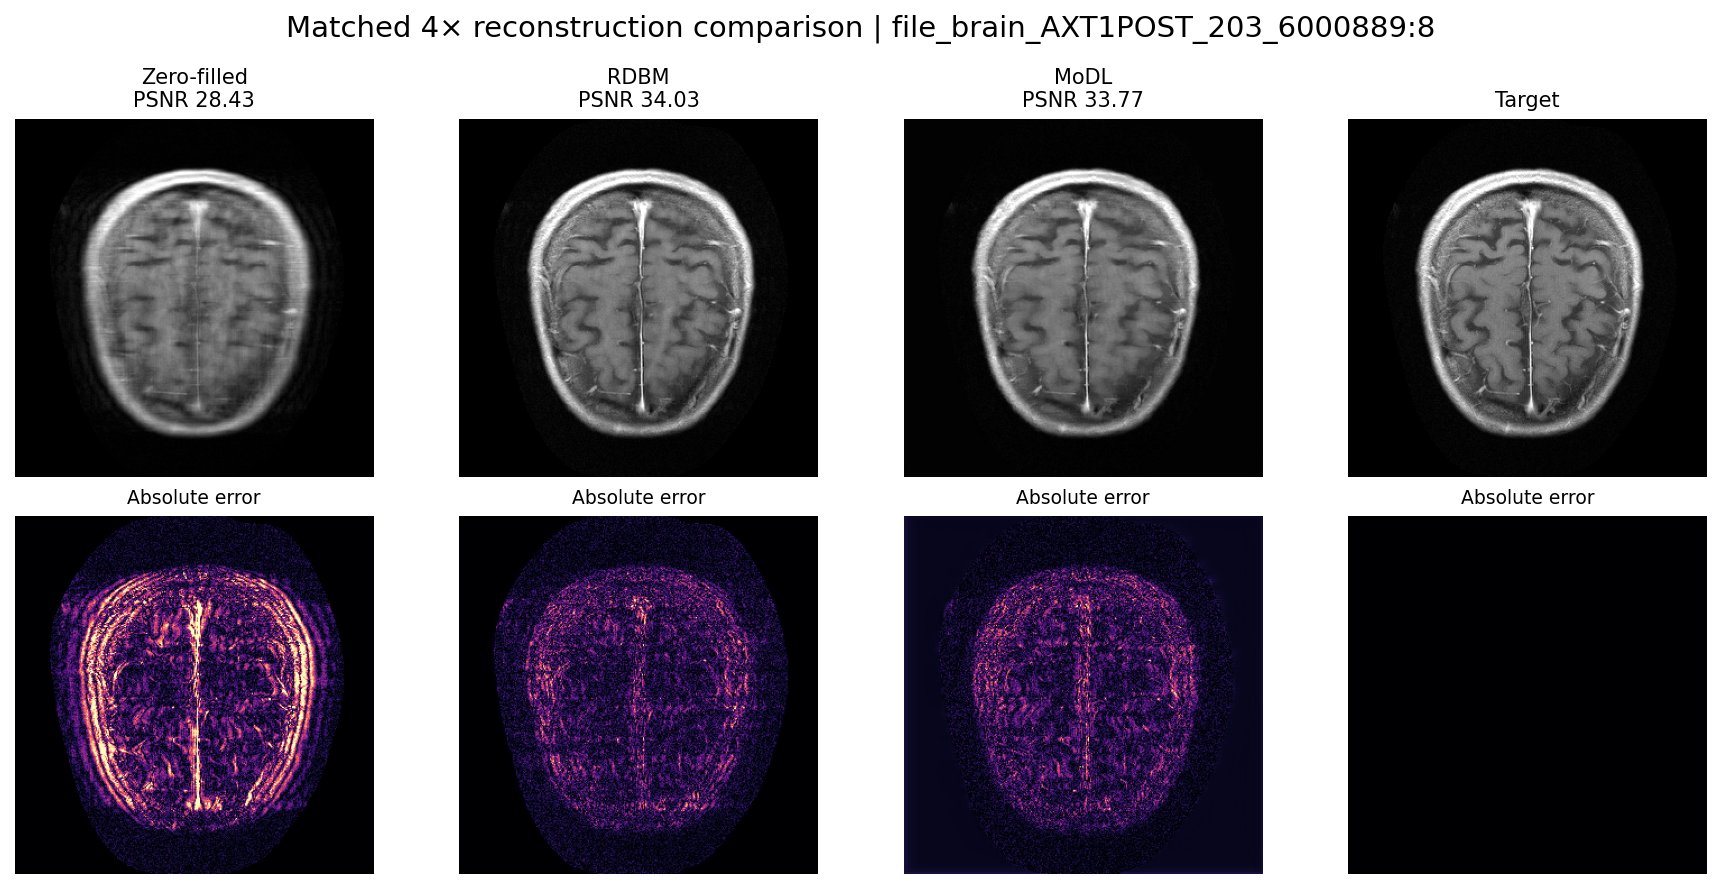

Method,Nmse,Psnr,Ssim
zero_filled,0.0429,28.4294,0.8206
modl,0.0145,33.7723,0.8131
rdbm,0.0153,34.0334,0.9148


In [12]:
display(Image(filename=str(ROOT / 'results/modl_evaluation/qualitative/model_comparison.png')))
metric_rows = [{'Method': name, **values} for name, values in progression['metrics'].items()]
show_table(metric_rows, [(key, key.replace('_', ' ').title()) for key in ['Method', 'nmse', 'psnr', 'ssim']])

## Interpretation

- Validation selected steps **94,900, 37,960, 18,980, and 18,980** for 2×, 4×,
  6×, and 8×, respectively; additional exposure did not consistently improve validation PSNR.
- A validation-only, no-retraining early-exit ablation selected stage 7 at 2×; it
  improved validation PSNR, SSIM, and NMSE over stage 10. Earlier exits at the other
  rates created SSIM-versus-PSNR/NMSE tradeoffs, so stage 10 was retained.
- MoDL improves test PSNR over zero-filled reconstruction at every rate, reaching
  39.66, 34.80, 30.84, and 29.82 dB from 2× through 8×.
- SSIM and complex NMSE do not follow PSNR consistently. At 2×, 4×, and 6×,
  magnitude SSIM is below the zero-filled reference; complex NMSE is also worse overall.
- The 4× RDBM remains stronger on the present image-quality metrics, while MoDL is
  substantially faster per slice.
- Acquisition-level results should accompany aggregate metrics because a small number
  of AXFLAIR failures strongly affect complex NMSE.

These are first-run results on a small 14-volume test split, so they should be reported
with the acquisition breakdown rather than as a single aggregate score alone.